# TPI · Módulo 3b — Reconstrucción tomográfica (simulación)
**PSIB 2026Q2 · Grupo 12** — Lautersztein, Reggio, Ballester
*Detección de leucemia linfoblástica aguda (LLA) en imágenes de frotis de sangre periférica*

La consigna incluye la **reconstrucción** entre las etapas obligatorias del preprocesamiento. Las imágenes de frotis se adquieren con un microscopio óptico, no por proyecciones, así que no hay una reconstrucción real que hacer. Por eso la etapa se evalúa mediante una **simulación**: a cada imagen se le calcula la **transformada de Radon** (como si se hubiera adquirido por proyecciones con un tomógrafo), se la **reconstruye** con los métodos vistos en la materia y se pasa la imagen reconstruida por el **pipeline completo** del Módulo 3.

**Pregunta:** ¿cuánto se degradan la segmentación y los descriptores según el **método de reconstrucción** y la **cantidad de proyecciones**? Es el mismo esquema que el experimento de compresión del Módulo 3 (sección 6): ambos miden la robustez del pipeline ante una degradación de la imagen.

**Métodos** (clase de Reconstrucción Tomográfica):
- **SBP** (*simple backprojection*): retroproyección sin filtrar. No es la inversa de Radon: cada punto se "esparce" a lo largo de las rectas de proyección y la imagen queda borrosa (equivale a convolucionar con 1/r).
- **FBP** (*filtered backprojection*): antes de retroproyectar, cada proyección se filtra con el **filtro rampa** |ω|, que compensa esa sobreponderación de las bajas frecuencias (teorema de la sección central de Fourier).
- **SART** (*simultaneous algebraic reconstruction technique*): método **iterativo** que plantea la reconstrucción como un sistema lineal **A x = b** y lo resuelve actualizando la imagen con todas las proyecciones de un ángulo a la vez (variante de ART/Kaczmarz), con relajación λ = 0,15. Se usan 2 iteraciones.

**Cantidad de proyecciones:** 180, 90, 45 y 18 ángulos equiespaciados en [0°, 180°). Con menos proyecciones el muestreo angular es insuficiente y aparecen **artefactos de rayas** (*streaks*).

## 0. Carga y funciones del Módulo 3
Las mismas funciones del Módulo 3, sin cambios: carga del dataset, corrección de iluminación, segmentación por *k*-means global (con semilla fija) y descriptores de forma, color y textura.

In [1]:
import os, glob
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import spearmanr
from skimage import measure, segmentation
import kagglehub

RUTA = kagglehub.dataset_download('mehradaria/leukemia')
df = pd.DataFrame({'ruta': sorted(glob.glob(f'{RUTA}/**/*.jp*g', recursive=True))})
df['tipo'] = np.where(df.ruta.str.contains('segment', case=False), 'segmentada', 'original')
df['subtipo'] = df.ruta.map(lambda p: os.path.basename(os.path.dirname(p)))
df['clase'] = np.where(df.subtipo.str.contains('benign', case=False), 'no patológica', 'patológica')
df['archivo'] = df.ruta.map(os.path.basename)

org = df[df.tipo == 'original'].reset_index(drop=True)
seg = df[df.tipo == 'segmentada'].set_index(['subtipo', 'archivo']).ruta
org['ruta_seg'] = org.set_index(['subtipo', 'archivo']).index.map(seg.get)
org = org[org.ruta_seg.notna()].reset_index(drop=True)
leer = lambda ruta: cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)
subtipos = sorted(org.subtipo.unique())
print(f'Imágenes: {len(org)}')

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imágenes: 3256


In [2]:
# --- Módulo 1: corrección de iluminación (cierre morfológico) ---
TAM_EE = 1 / 3

def estimar_campo(v):
    n = max(v.shape)
    ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (int(n * TAM_EE) | 1,) * 2)
    return cv2.GaussianBlur(cv2.morphologyEx(v, cv2.MORPH_CLOSE, ee), (0, 0), n / 16)

def preprocesar(rgb):
    h, s, v = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))
    campo = np.maximum(estimar_campo(v.astype(np.float32)), 1)
    v = np.clip(v / campo * campo.mean(), 0, 255).astype(np.uint8)
    return cv2.cvtColor(cv2.merge([h, s, v]), cv2.COLOR_HSV2RGB)

# --- Módulo 2: limpieza morfológica y segmentación de referencia (sólo para validar) ---
AREA_MIN_NUC = 100     # px²: debajo es resto/ruido (histograma del área de componentes, commit anterior del Módulo 3)

def limpiar(mask, area_min=25):
    m = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, etq, stats, _ = cv2.connectedComponentsWithStats(m)
    grandes = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= area_min]
    return np.isin(etq, grandes)

def sin_marca(mask):
    # Descarta la esquina inferior derecha (marca de agua / barra de escala).
    m = mask.copy(); h, w = m.shape
    m[int(h * 0.88):, int(w * 0.75):] = False
    return m

def mascara_celula(ruta_seg):
    # Segmentación de referencia del dataset (células completas). Sólo se usa para diagnóstico y validación.
    return cv2.cvtColor(leer(ruta_seg), cv2.COLOR_RGB2GRAY) > 10

def dice(a, b):
    return 2 * (a & b).sum() / (a.sum() + b.sum() + 1e-9)

In [3]:
def kmeans_clusters(rgb, k=3):
    # k-means en (a*, b*) sobre todos los píxeles. Devuelve etiquetas ordenadas por croma: 0 = fondo, ..., k-1 = núcleo.
    cv2.setRNGSeed(42)    # semilla fija: la inicialización de k-means es aleatoria; así los resultados son reproducibles
    ab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)[..., 1:].reshape(-1, 2) - 128
    _, etq, centros = cv2.kmeans(ab, k, None, (cv2.TERM_CRITERIA_EPS, 20, 0.5), 3, cv2.KMEANS_PP_CENTERS)
    orden = np.argsort(np.argsort(np.linalg.norm(centros, axis=1)))     # rango de croma de cada cluster
    return orden[etq.ravel()].reshape(rgb.shape[:2])

def segmentar_componentes(rgb):
    # Núcleos etiquetados (1..N) y máscara de píxeles teñidos (no fondo).
    cl = kmeans_clusters(rgb)
    nuc = sin_marca(ndi.binary_fill_holes(limpiar(cl == 2, AREA_MIN_NUC)))    # = segmentar_kmeans_global del Módulo 2
    # Teñido = no es fondo por color (cluster >= 1) O es más oscuro que el fondo (Otsu sobre L*):
    # el citoplasma es celeste muy pálido y por croma sólo puede confundirse con el fondo, pero es más oscuro.
    L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    umbral_L, _ = cv2.threshold(L, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    tenido = sin_marca(limpiar((cl >= 1) | (L < umbral_L))) | nuc
    return measure.label(nuc), tenido

def crecer_celulas(nucleos, tenido, F):
    # Célula de cada núcleo: píxeles teñidos más cercanos a ese núcleo, dentro de un anillo de ancho (F-1)·r_eq.
    if nucleos.max() == 0:
        return np.zeros_like(nucleos)
    dist, (iy, ix) = ndi.distance_transform_edt(nucleos == 0, return_indices=True)
    mas_cercano = nucleos[iy, ix]
    areas = np.bincount(nucleos.ravel())
    r_eq = np.sqrt(areas / np.pi)
    celulas = np.where(tenido & (dist <= (F - 1) * r_eq[mas_cercano]), mas_cercano, 0)
    celulas[nucleos > 0] = nucleos[nucleos > 0]
    salida = np.zeros_like(celulas)
    for i in range(1, nucleos.max() + 1):                     # sólo la parte conectada al núcleo, sin huecos
        comp = measure.label(celulas == i)
        ids = np.unique(comp[nucleos == i]); ids = ids[ids > 0]
        salida[ndi.binary_fill_holes(np.isin(comp, ids))] = i
    return salida

In [4]:
FORMA = ['area', 'perimetro', 'circularidad', 'excentricidad', 'solidez', 'n_nucleos', 'frac_nuclear']

def descriptores_forma(nucleos):
    # Resumen por imagen: mediana por núcleo (sin los que tocan el borde) + n_nucleos + frac_nuclear.
    d = dict(n_nucleos=int(nucleos.max()), frac_nuclear=(nucleos > 0).mean())
    internos = segmentation.clear_border(nucleos)
    usar = internos if internos.max() > 0 else nucleos
    filas = []
    for p in measure.regionprops(usar):
        per = p.perimeter
        filas.append(dict(area=p.area, perimetro=per,
                          circularidad=4 * np.pi * p.area / per**2 if per > 0 else np.nan,
                          excentricidad=p.eccentricity, solidez=p.solidity))
    if not filas:
        return {**{k: np.nan for k in FORMA}, **d}
    return {**pd.DataFrame(filas).median().to_dict(), **d}

In [5]:
COLOR = ['H_media', 'H_desvio', 'S_media', 'S_desvio', 'a_media', 'a_desvio', 'b_media', 'b_desvio', 'S_rel']

def media_desvio_circular(h):
    # Media y desvío circulares del tono de OpenCV (H en [0, 180) -> ángulo en [0, 2π)).
    ang = h.astype(float) * 2 * np.pi / 180
    c, s = np.cos(ang).mean(), np.sin(ang).mean()
    R = np.hypot(c, s)
    media = (np.arctan2(s, c) % (2 * np.pi)) * 180 / (2 * np.pi)
    desvio = np.sqrt(-2 * np.log(max(R, 1e-12))) * 180 / (2 * np.pi)
    return media, desvio

def descriptores_color(rgb, nucleos, tenido):
    nuc = nucleos > 0
    if not nuc.any():
        return {k: np.nan for k in COLOR}
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(float) - [0, 128, 128]
    h_m, h_d = media_desvio_circular(hsv[..., 0][nuc])
    s, a, b = hsv[..., 1][nuc].astype(float), lab[..., 1][nuc], lab[..., 2][nuc]
    resto = tenido & ~nuc
    s_resto = hsv[..., 1][resto].mean() if resto.any() else np.nan
    return dict(H_media=h_m, H_desvio=h_d, S_media=s.mean(), S_desvio=s.std(),
                a_media=a.mean(), a_desvio=a.std(), b_media=b.mean(), b_desvio=b.std(),
                S_rel=s.mean() / s_resto if s_resto and s_resto > 0 else np.nan)

In [6]:
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

NIVELES = 32
DISTANCIAS = [1, 3]
ANGULOS = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
PROPS = {'contrast': 'contraste', 'homogeneity': 'homogeneidad', 'energy': 'energia', 'correlation': 'correlacion'}
TEXTURA = [f'glcm_{v}_d{d}' for d in DISTANCIAS for v in PROPS.values()] + \
          ['lbp_entropia', 'lbp_plano', 'lbp_borde', 'lbp_no_uniforme']

def gris_normalizado(rgb, nuc):
    # Gris reescalado a [0, 1] con los percentiles 1 y 99 de los píxeles nucleares de ESTA imagen.
    g = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(float)
    lo, hi = np.percentile(g[nuc], [1, 99])
    return np.clip((g - lo) / max(hi - lo, 1), 0, 1)

def glcm_nucleo(q, region):
    # GLCM de un núcleo: niveles 1..NIVELES dentro del núcleo, 0 afuera (los pares con 0 se descartan).
    r0, c0, r1, c1 = region.bbox
    parche = np.where(region.image, q[r0:r1, c0:c1], 0).astype(np.uint8)
    P = graycomatrix(parche, DISTANCIAS, ANGULOS, levels=NIVELES + 1, symmetric=True)[1:, 1:].astype(float)
    if (P.sum(axis=(0, 1)) == 0).any():
        return None
    fila = {}
    for prop, nombre in PROPS.items():
        valores = graycoprops(P, prop)                       # [n_distancias x n_angulos]
        with np.errstate(all='ignore'):
            for k, d in enumerate(DISTANCIAS):
                fila[f'glcm_{nombre}_d{d}'] = np.nanmean(valores[k])
    return fila

def descriptores_textura(rgb, nucleos):
    nuc = nucleos > 0
    if not nuc.any():
        return {k: np.nan for k in TEXTURA}
    gn = gris_normalizado(rgb, nuc)
    q = (gn * (NIVELES - 1)).round().astype(np.uint8) + 1        # 1..NIVELES
    internos = segmentation.clear_border(nucleos)
    usar = internos if internos.max() > 0 else nucleos
    filas = [f for f in (glcm_nucleo(q, reg) for reg in measure.regionprops(usar)) if f]
    d = pd.DataFrame(filas).median().to_dict() if filas else {k: np.nan for k in TEXTURA if k.startswith('glcm')}
    lbp = local_binary_pattern((gn * 255).astype(np.uint8), P=8, R=1, method='uniform')
    interior = ndi.binary_erosion(nuc)
    codigos = lbp[interior].astype(int) if interior.any() else lbp[nuc].astype(int)
    h = np.bincount(codigos, minlength=10) / len(codigos)                   # códigos 0..9
    hp = h[h > 0]
    d.update(lbp_entropia=-(hp * np.log2(hp)).sum(), lbp_plano=h[8], lbp_borde=h[3:6].sum(), lbp_no_uniforme=h[9])
    return d

## 1. Simulación de la adquisición y reconstrucción
Cada canal RGB se procesa por separado como una imagen en escala de grises: se calcula su **sinograma** con 180 proyecciones (`circle=False`, para no perder las esquinas de la imagen), y las adquisiciones con menos proyecciones se obtienen tomando un subconjunto equiespaciado de esos ángulos.

**Calibración de intensidad.** SBP no conserva la escala de intensidades (su salida es mucho mayor que la imagen original) y FBP/SART pueden tener un pequeño corrimiento. Para que el pipeline reciba una imagen comparable, cada canal reconstruido se ajusta con una transformación lineal (ganancia y offset por mínimos cuadrados respecto del canal original) y se recorta a [0, 255]. Esto corrige sólo la escala global, no la forma ni el detalle, así que no "esconde" los artefactos de la reconstrucción.

In [7]:
from skimage.transform import radon, iradon, iradon_sart
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

N_PROYECCIONES = [180, 90, 45, 18]
METODOS = ['SBP', 'FBP', 'SART']
ITER_SART = 2
THETA_COMPLETO = np.linspace(0, 180, max(N_PROYECCIONES), endpoint=False)

def sinograma(canal):
    # Transformada de Radon de un canal (180 ángulos en [0°, 180°)).
    return radon(canal.astype(float), THETA_COMPLETO, circle=False)

def subconjunto(sino, n):
    # Sinograma con n proyecciones equiespaciadas (subconjunto de las 180).
    idx = np.round(np.linspace(0, len(THETA_COMPLETO), n, endpoint=False)).astype(int)
    return sino[:, idx], THETA_COMPLETO[idx]

def reconstruir(sino, theta, metodo, tam):
    if metodo == 'SBP':
        return iradon(sino, theta, filter_name=None, circle=False, output_size=tam)
    if metodo == 'FBP':
        return iradon(sino, theta, filter_name='ramp', circle=False, output_size=tam)
    rec = None
    for _ in range(ITER_SART):
        rec = iradon_sart(sino, theta, image=rec, relaxation=0.15)
    o = (rec.shape[0] - tam) // 2                      # SART reconstruye el cuadrado del sinograma: se recorta el centro
    return rec[o:o + tam, o:o + tam]

def calibrar(rec, original):
    # Ganancia y offset por mínimos cuadrados -> misma escala de intensidades que el original.
    A = np.c_[rec.ravel(), np.ones(rec.size)]
    g, b = np.linalg.lstsq(A, original.ravel().astype(float), rcond=None)[0]
    return np.clip(rec * g + b, 0, 255).astype(np.uint8)

def reconstruir_rgb(rgb, sinos, metodo, n):
    canales = []
    for k in range(3):
        sino_n, theta_n = subconjunto(sinos[k], n)
        canales.append(calibrar(reconstruir(sino_n, theta_n, metodo, rgb.shape[0]), rgb[..., k]))
    return np.dstack(canales)

def pipeline(rgb_crudo):
    # Imagen RGB -> (máscara de núcleos, dict con todos los descriptores). Mismo pipeline que el Módulo 3.
    rgb = preprocesar(rgb_crudo)
    nucleos, tenido = segmentar_componentes(rgb)
    d = {**descriptores_forma(nucleos), **descriptores_color(rgb, nucleos, tenido), **descriptores_textura(rgb, nucleos)}
    return nucleos > 0, d

### 1.1 Ejemplo
Una imagen benigna: el sinograma (cada columna es una proyección) y la reconstrucción con cada método, con 180 y con 18 proyecciones. Debajo de cada imagen, PSNR y SSIM respecto de la original.

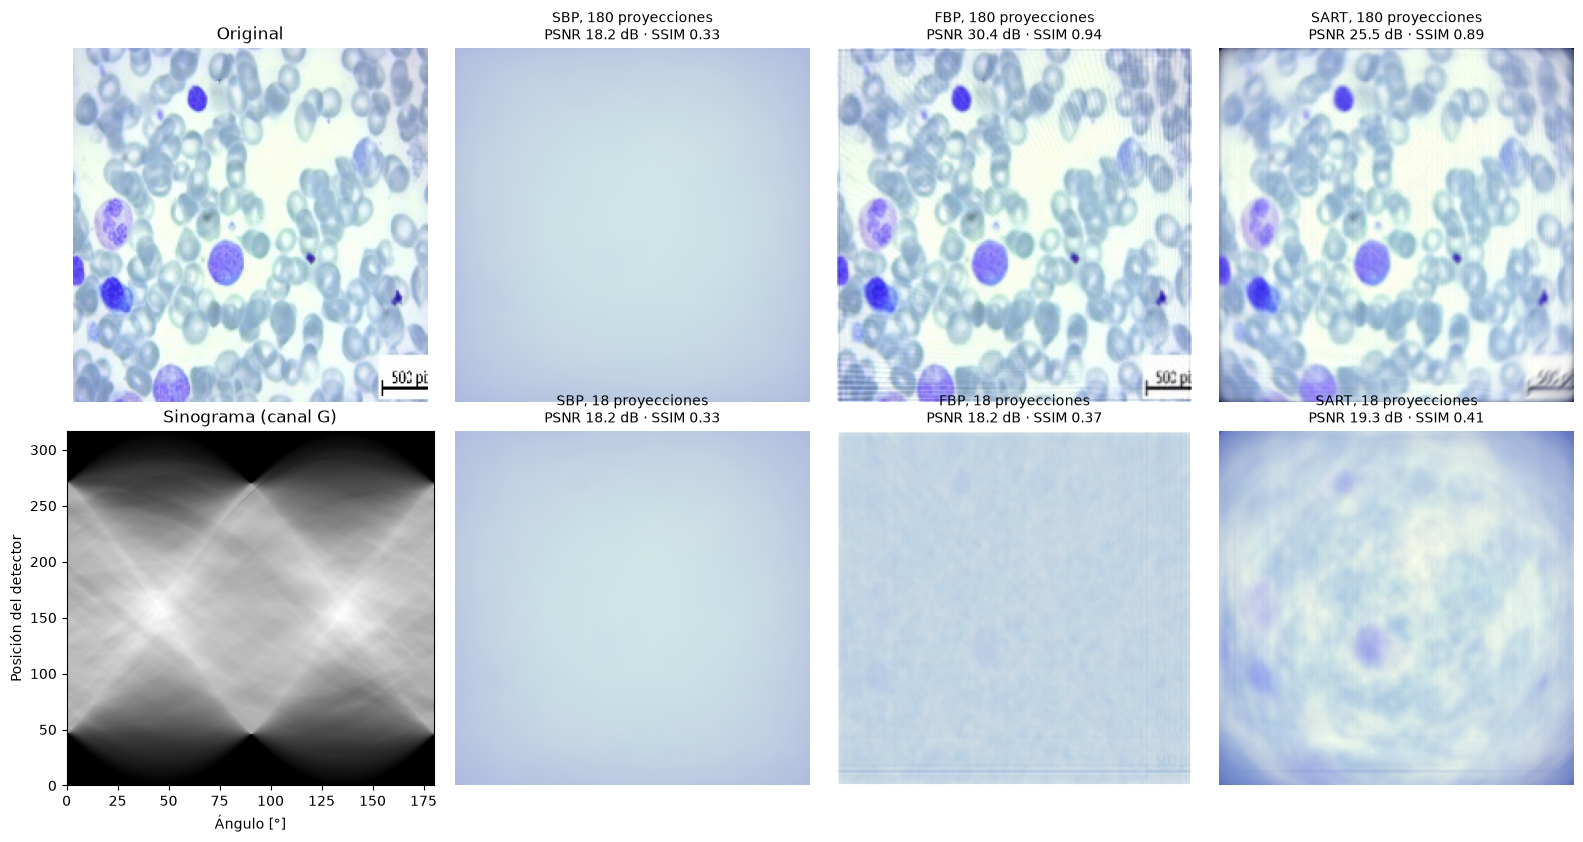

In [8]:
r = org[org.subtipo.str.contains('Benign')].sample(1, random_state=3).iloc[0]
rgb = leer(r.ruta)
sinos = [sinograma(rgb[..., k]) for k in range(3)]
fig, ax = plt.subplots(2, 4, figsize=(16, 8.4))
ax[0, 0].imshow(rgb); ax[0, 0].set_title('Original')
ax[1, 0].imshow(sinos[1], cmap='gray', aspect='auto', extent=(0, 180, 0, sinos[1].shape[0]))
ax[1, 0].set(title='Sinograma (canal G)', xlabel='Ángulo [°]', ylabel='Posición del detector')
for i, n in enumerate([180, 18]):
    for j, m in enumerate(METODOS, start=1):
        rec = reconstruir_rgb(rgb, sinos, m, n)
        a = ax[i, j]
        a.imshow(rec)
        a.set_title(f'{m}, {n} proyecciones\nPSNR {peak_signal_noise_ratio(rgb, rec):.1f} dB · SSIM {structural_similarity(rgb, rec, channel_axis=2):.2f}', fontsize=10)
for a in ax.ravel()[[0, 1, 2, 3, 5, 6, 7]]:
    a.axis('off')
plt.tight_layout()

## 2. Efecto sobre la segmentación y los descriptores
Muestra estratificada de **8 imágenes por subtipo** (32 imágenes; SART es costoso: tarda varios segundos por imagen y configuración). Para cada imagen y cada combinación de método × cantidad de proyecciones (12 configuraciones) se mide:
- **PSNR** y **SSIM** entre la imagen original y la reconstruida;
- **Dice** entre la máscara de núcleos obtenida con la imagen original y con la reconstruida;
- **cambio relativo (%)** de los mismos descriptores clave que en el experimento de compresión.

La semilla de *k*-means está fija, así que las diferencias se deben sólo a la reconstrucción.

In [9]:
CLAVE = ['area', 'circularidad', 'S_desvio', 'S_rel', 'glcm_contraste_d1', 'glcm_homogeneidad_d1', 'lbp_entropia']
muestra_r = org.groupby('subtipo').sample(8, random_state=0)
filas = []
for r in muestra_r.itertuples():
    rgb = leer(r.ruta)
    m0, d0 = pipeline(rgb)
    sinos = [sinograma(rgb[..., k]) for k in range(3)]
    for metodo in METODOS:
        for n in N_PROYECCIONES:
            rec = reconstruir_rgb(rgb, sinos, metodo, n)
            mq, dq = pipeline(rec)
            fila = dict(subtipo=r.subtipo, metodo=metodo, proyecciones=n,
                        psnr=peak_signal_noise_ratio(rgb, rec),
                        ssim=structural_similarity(rgb, rec, channel_axis=2),
                        dice_nucleo=dice(m0, mq), n_nucleos_rec=dq['n_nucleos'], n_nucleos_orig=d0['n_nucleos'])
            for k in CLAVE:
                fila[f'cambio_{k}'] = 100 * abs(dq[k] - d0[k]) / (abs(d0[k]) + 1e-9) if np.isfinite(dq[k]) else np.nan
            filas.append(fila)
recon = pd.DataFrame(filas)
recon.groupby(['metodo', 'proyecciones'], sort=False)[['psnr', 'ssim', 'dice_nucleo']].mean().round(3)

psnr   ssim  dice_nucleo
metodo proyecciones                            
SBP    180           18.930  0.477        0.160
       90            18.930  0.477        0.156
       45            18.930  0.477        0.147
       18            18.930  0.477        0.156
FBP    180           33.189  0.948        0.985
       90            26.657  0.830        0.953
       45            22.992  0.670        0.852
       18            19.077  0.504        0.425
SART   180           27.598  0.885        0.968
       90            25.207  0.801        0.896
       45            22.601  0.672        0.761
       18            20.370  0.547        0.415

In [10]:
# Cambio relativo de los descriptores clave (mediana, %) por método y cantidad de proyecciones
recon.groupby(['metodo', 'proyecciones'], sort=False)[[f'cambio_{k}' for k in CLAVE]].median().round(1)

cambio_area  cambio_circularidad  cambio_S_desvio  \
metodo proyecciones                                                      
SBP    180               10946.8                 11.5             80.5   
       90                10617.1                 12.7             80.5   
       45                10136.2                 15.3             82.0   
       18                10110.1                 15.9             83.0   
FBP    180                   1.2                  1.9              1.8   
       90                    7.6                  5.1             13.8   
       45                   12.0                 21.5             33.6   
       18                   44.4                 51.8             88.5   
SART   180                   1.4                  2.5              6.7   
       90                    2.9                  2.6             11.1   
       45                    9.1                  3.3             13.3   
       18                   35.0                 20.0             22.0   

                     cambio_S_rel  cambio_glcm_contraste_d1  \
metodo proyecciones                                           
SBP    180                   33.9                      95.9   
       90                    32.6                      95.9   
       45                    30.9                      95.2   
       18                    33.4                      94.0   
FBP    180                    2.1                      34.0   
       90                    18.1                      14.6   
       45                    30.2                      20.2   
       18                    43.5                      63.4   
SART   180                    8.6                      37.9   
       90                    11.3                      65.0   
       45                    10.0                      77.7   
       18                    18.8                      86.6   

                     cambio_glcm_homogeneidad_d1  cambio_lbp_entropia  
metodo proyecciones                                                    
SBP    180                                 165.6                 54.2  
       90                                  165.7                 52.2  
       45                                  173.8                 53.3  
       18                                  163.9                 54.5  
FBP    180                                  20.9                  1.3  
       90                                    5.8                  1.2  
       45                                   11.2                  2.6  
       18                                   30.9                  7.8  
SART   180                                  22.6                  2.6  
       90                                   43.7                  5.5  
       45                                   58.6                 10.5  
       18                                   79.6                 10.6

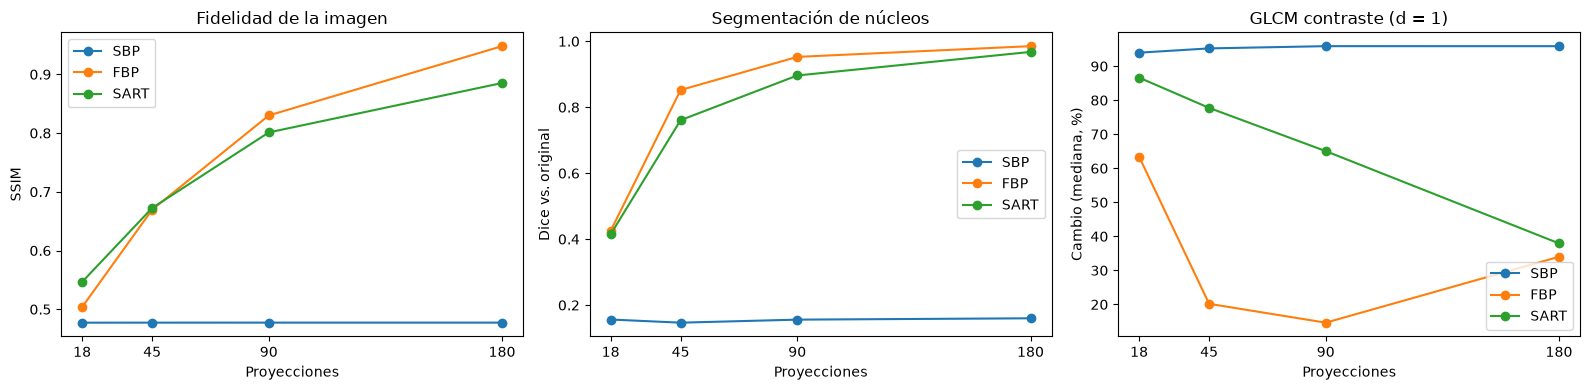

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for m in METODOS:
    g = recon[recon.metodo == m].groupby('proyecciones').mean(numeric_only=True)
    ax[0].plot(g.index, g.ssim, marker='o', label=m)
    ax[1].plot(g.index, g.dice_nucleo, marker='o', label=m)
    ax[2].plot(g.index, recon[recon.metodo == m].groupby('proyecciones').cambio_glcm_contraste_d1.median(), marker='o', label=m)
ax[0].set(xlabel='Proyecciones', ylabel='SSIM', title='Fidelidad de la imagen')
ax[1].set(xlabel='Proyecciones', ylabel='Dice vs. original', title='Segmentación de núcleos')
ax[2].set(xlabel='Proyecciones', ylabel='Cambio (mediana, %)', title='GLCM contraste (d = 1)')
for a in ax:
    a.legend(); a.set_xticks(N_PROYECCIONES)
plt.tight_layout()

## 3. Observaciones
- **SBP no sirve para el pipeline, como predice la teoría.** Sin filtrar, la retroproyección no es la inversa de Radon: la imagen queda borrosa (SSIM ≈ 0,48, PSNR ≈ 19 dB) **independientemente de la cantidad de proyecciones**, porque el error dominante no es el muestreo angular sino la ponderación 1/r. Los núcleos se funden con el entorno y la segmentación se destruye (Dice ≈ 0,16; el *k*-means termina marcando manchas difusas mucho más grandes que los núcleos).
- **FBP con muestreo completo es casi transparente para la forma y el color.** Con 180 proyecciones: PSNR 33 dB, SSIM 0,95, Dice 0,985 y cambios de área, circularidad, desvío de S y S_rel de ~1–2 %. Al reducir las proyecciones aparecen artefactos de rayas y todo se degrada: Dice 0,95 (90), 0,85 (45) y 0,43 (18).
- **SART (2 iteraciones) no supera a FBP con muestreo completo** (Dice 0,968 vs. 0,985 con 180 proyecciones): con pocas iteraciones el método iterativo todavía no convergió. Con **pocas proyecciones** (18) los dos métodos segmentan igual de mal (Dice ≈ 0,42), pero SART altera bastante menos la forma y el color (circularidad 20 % vs. 52 %, desvío de S 22 % vs. 89 %), porque el método algebraico produce menos rayas. A cambio, **suaviza** la imagen y afecta más la textura (homogeneidad GLCM 80 % vs. 31 %).
- **La textura GLCM es, otra vez, lo más sensible.** Incluso con FBP y 180 proyecciones el contraste cambia ~34 % y la homogeneidad ~21 %: el filtro rampa amplifica las altas frecuencias y los errores de interpolación a escala de píxel, que es justamente la escala que mide la GLCM con d = 1. El cambio no es monótono con la cantidad de proyecciones (con 90 el contraste cambia menos que con 180), porque se combinan dos efectos opuestos: el ruido de alta frecuencia que agrega el filtro y el suavizado que producen los artefactos. LBP, en cambio, resiste bien con FBP (cambio de entropía < 3 % hasta 45 proyecciones).
- **Conclusión:** si las imágenes provinieran de una reconstrucción por proyecciones, el pipeline necesitaría **FBP (no SBP) con muestreo angular completo** para que la segmentación y los descriptores de forma y color sean confiables; los descriptores de textura GLCM no serían comparables con los obtenidos sobre imágenes adquiridas directamente. Es la misma conclusión que el experimento de compresión: la textura es la parte más frágil del análisis frente a cualquier degradación de la imagen.
- *Limitación:* muestra de 32 imágenes (8 por subtipo) por el costo computacional de SART; la reconstrucción se simula canal por canal sobre imágenes que no fueron adquiridas por proyecciones.